## 0. 設定

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib_fontja
from sklearn.decomposition import PCA

In [2]:
DATA_DIR = Path("../data/CMAPSSData")
OUT_PATH = Path("../web/public/data.json")  # React(Vite)から fetch("data.json") で読める場所
DATASET = "FD001"

settings = ["op1", "op2", "op3"]
sensor_cols = [f"s{i}" for i in range(1, 22)]
columns = ["エンジンID", "サイクル", *settings, *sensor_cols]

N_HEALTHY = 30        # 各エンジンの最初の何サイクルを正常とみなすか
WINDOW = 10           # 移動平均のウインドウ(サイクル)
STD_THRESHOLD = 1e-4  # 運転条件内の標準偏差がこの閾値以下のセンサーは除外
VAR_RATIO = 0.90      # 異常検知の PCA で残す累積寄与率
LIMIT_Q = 0.99        # 管理限界: 正常区間の何%点を閾値にするか
CONSEC = 5            # 異常度 1 以上がこのサイクル分続いたら「異常と判定」
MAP_METHOD = "pca"    # 2次元マップの作り方: "pca" または "umap"

assert N_HEALTHY >= WINDOW, "正常区間は移動平均のウインドウ以上にする"

## 1. データ読み込み

In [3]:
# データ読み込み、ソート
df = pd.read_csv(DATA_DIR / f"train_{DATASET}.txt", sep=r"\s+", header=None)
df.columns = columns
df = df.sort_values(["エンジンID", "サイクル"]).reset_index(drop=True)

# 運転条件ごとに「条件番号」を付与
key = (df[settings].round({"op1": 0, "op2": 2, "op3": 0}) + 0.0).apply(tuple, axis=1)
cond_map = {k: i for i, k in enumerate(sorted(key.unique()))}
df["condition"] = key.map(cond_map)

# 故障までの残り寿命(RUL)を計算
life = df.groupby("エンジンID")["サイクル"].max()
df["RUL"] = df["エンジンID"].map(life) - df["サイクル"]  # 故障時点で 0
df["healthy"] = df["サイクル"] <= N_HEALTHY

In [4]:
# サイクルが連続しているか確認
contiguous = df.groupby("エンジンID")["サイクル"].apply(lambda c: (c.to_numpy() == np.arange(1, len(c) + 1)).all())
assert contiguous.all(), f"サイクルが連続していないエンジン: {contiguous[~contiguous].index.tolist()}"

print(f"{DATASET}: {len(df):,} 行, エンジン {len(life)} 台, 運転条件 {len(cond_map)} 個, 寿命 {life.min()}〜{life.max()} サイクル")

FD001: 20,631 行, エンジン 100 台, 運転条件 1 個, 寿命 128〜362 サイクル


## 2. センサー選択

In [5]:
# センサーの除外
by_cond = df.groupby("condition")[sensor_cols]
min_std = by_cond.std().min()
min_nunique = by_cond.nunique().min() # 各運転条件内でのユニーク値の数の最小値

sensors = [s for s in sensor_cols if min_std[s] > STD_THRESHOLD and min_nunique[s] > 2] # 標準偏差が閾値未満のセンサーおよびユニーク値が 2 以下（２値）のセンサーは除外
print("除外:", [s for s in sensor_cols if s not in sensors])
print("採用:", sensors)

除外: ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
採用: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## 3. 正常区間を基準にした標準化と移動平均

In [6]:
healthy_stats = df[df["healthy"]].groupby("condition")[sensors].agg(["mean", "std"])
mu = healthy_stats.xs("mean", axis=1, level=1).reindex(df["condition"]).to_numpy()
sd = healthy_stats.xs("std", axis=1, level=1).reindex(df["condition"]).to_numpy()
print('平均値:', mu[0])
print('標準偏差:', sd[0])
# 値が大きく異なるセンサー間でも比較できるように標準化
z = pd.DataFrame((df[sensors].to_numpy() - mu) / sd, columns=sensors, index=df.index)

# ノイズ除去のため移動平均を取り平滑化
z_ma = z.groupby(df["エンジンID"]).transform(lambda x: x.rolling(WINDOW).mean().bfill()) # WINDOW未満のサイクルはサンプル少なくて不安定なので、bfill()で後ろの値で埋める
z_ma.describe().T[["mean", "std", "min", "max"]].round(2)

平均値: [6.42383217e+02 1.58689848e+03 1.40283102e+03 5.53947667e+02
 2.38805922e+03 9.05606208e+03 4.73560767e+01 5.21904853e+02
 2.38805674e+03 8.13738407e+03 8.41838183e+00 3.92270000e+02
 3.89322500e+01 2.33591721e+01]
標準偏差: [0.3796104  4.64901448 5.93174972 0.62383658 0.05505852 8.40395249
 0.17689339 0.50685311 0.05504043 7.95660108 0.02643531 1.14260018
 0.12961342 0.07872655]


,mean,std,min,max
s2,0.71,1.02,-1.62,3.85
s3,0.71,0.97,-1.47,4.24
s4,0.93,1.29,-1.79,4.67
s7,-0.85,1.21,-4.53,1.66
s8,0.61,1.12,-1.68,4.59
s9,0.98,2.35,-3.26,18.80
s11,0.95,1.33,-1.58,4.70
s12,-0.88,1.27,-4.72,1.69
s13,0.65,1.14,-1.70,4.84
s14,0.72,2.15,-4.08,16.82


## 4. 異常度:ホテリングの T² と SPE(Q統計量)

In [7]:
X = z_ma.to_numpy()
X_healthy = X[df["healthy"].to_numpy()] # 正常区間のみ学習させることで、異常な状態を判定できるようにする

cumvar = np.cumsum(PCA().fit(X_healthy).explained_variance_ratio_) # 累積寄与率の算出
n_comp = int(np.searchsorted(cumvar, VAR_RATIO) + 1) # 累積寄与率が閾値に達するまでの主成分数（インデックスではなく数にするため+1している）
pca = PCA(n_components=n_comp).fit(X_healthy) # 累積寄与率が閾値に達するまでの主成分を残す
print(f"残した主成分: {n_comp} / {len(sensors)} 個(累積寄与率 {cumvar[n_comp - 1]:.1%})")

scores = pca.transform(X)
t2 = (scores ** 2 / pca.explained_variance_).sum(axis=1) # 主成分空間でのホテリングT²統計量
spe = ((X - pca.inverse_transform(scores)) ** 2).sum(axis=1) # 主成分空間では表現できない方向の成分の大きさを算出

h = df["healthy"].to_numpy()
# 正常区間の 99%点を管理限界とする
t2_limit = np.quantile(t2[h], LIMIT_Q)
spe_limit = np.quantile(spe[h], LIMIT_Q)
print(f"管理限界: T² = {t2_limit:.2f}, SPE = {spe_limit:.2f}")

# 正規化（管理限界に対する大きさにする）して異常度を算出
df["t2"] = t2 / t2_limit
df["spe"] = spe / spe_limit
df["anomaly"] = df[["t2", "spe"]].max(axis=1) # 異常度 = T² と SPE の大きい方を採用

残した主成分: 2 / 14 個(累積寄与率 93.1%)
管理限界: T² = 5.23, SPE = 1.30


### 4-1. 異常度の推移

横軸は故障時点を 0 に揃えたサイクル。灰色の線が各エンジン、青線が各時点の中央値、赤の破線が管理限界(異常度 = 1)。

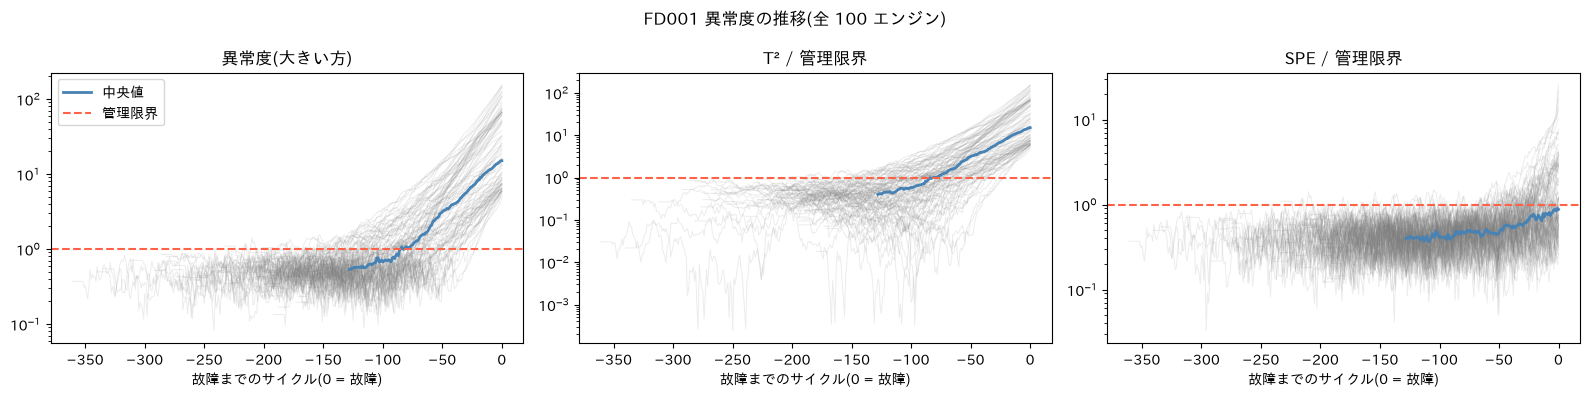

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for ax, col, label in zip(axes, ["anomaly", "t2", "spe"], ["異常度(大きい方)", "T² / 管理限界", "SPE / 管理限界"]):
    for _, g in df.groupby("エンジンID"):
        ax.plot(-g["RUL"], g[col], color="gray", alpha=0.15, linewidth=0.7)
    med = df.groupby("RUL")[col].median()
    med = med[med.index <= life.min()]  # 全エンジンがそろっている範囲だけ
    ax.plot(-med.index, med, color="steelblue", linewidth=2, label="中央値")
    ax.axhline(1, color="tomato", linestyle="--", label="管理限界")
    ax.set_yscale("log")
    ax.set_title(label)
    ax.set_xlabel("故障までのサイクル(0 = 故障)")
axes[0].legend()
fig.suptitle(f"{DATASET} 異常度の推移(全 {len(life)} エンジン)")
fig.tight_layout()
plt.show()

### 4-2. 故障の何サイクル前に気づけるか

異常度 1 以上が `CONSEC` サイクル続いた最初の時点を「異常と判定した時点」とし、そこから故障までのサイクル数を見る。

判定されたエンジン: 100 / 100 台
正常区間内で判定されたエンジン: 3 台
故障までのサイクル(中央値): 81


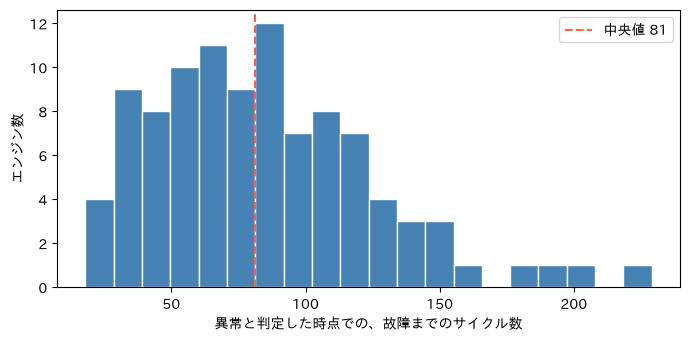

In [9]:
over = (df["anomaly"] >= 1).astype(int)
sustained = over.groupby(df["エンジンID"]).transform(lambda x: x.rolling(CONSEC).min()) == 1
detect = df[sustained].groupby("エンジンID").first() # 初めて異常と判定されたサイクルを抽出
lead = detect["RUL"].reindex(life.index)  # 判定時点での残りサイクル(判定されなければ NaN)

print(f"判定されたエンジン: {lead.notna().sum()} / {len(life)} 台")
print(f"正常区間内で判定されたエンジン: {(detect['サイクル'] <= N_HEALTHY).sum()} 台")
print(f"故障までのサイクル(中央値): {lead.median():.0f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(lead.dropna(), bins=20, color="steelblue", edgecolor="white")
ax.axvline(lead.median(), color="tomato", linestyle="--", label=f"中央値 {lead.median():.0f}")
ax.set_xlabel("異常と判定した時点での、故障までのサイクル数")
ax.set_ylabel("エンジン数")
ax.legend()
fig.tight_layout()
plt.show()

### 4-3. どのセンサーがずれているか

故障時点(RUL = 0)での標準化偏差(移動平均後)の、全エンジン平均。

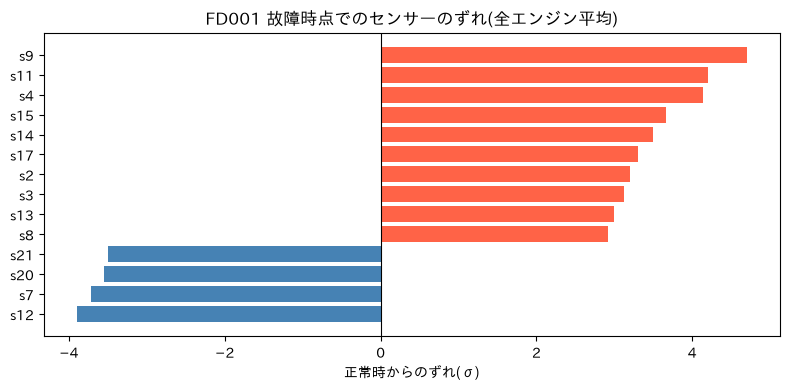

In [10]:
at_failure = z_ma[df["RUL"] == 0].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(at_failure.index, at_failure, color=np.where(at_failure > 0, "tomato", "steelblue"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("正常時からのずれ(σ)")
ax.set_title(f"{DATASET} 故障時点でのセンサーのずれ(全エンジン平均)")
fig.tight_layout()
plt.show()

## 5. 2次元マップの座標

In [11]:
if MAP_METHOD == "pca":
    map_pca = PCA(n_components=2).fit(X)
    xy = map_pca.transform(X)
    print("第1・第2主成分の寄与率:", map_pca.explained_variance_ratio_.round(3))
elif MAP_METHOD == "umap":
    import umap
    xy = umap.UMAP(n_components=2, random_state=0).fit_transform(X)
else:
    raise ValueError(MAP_METHOD)

if np.corrcoef(xy[:, 0], df["RUL"])[0, 1] > 0:  # 劣化(RUL が小さい)ほど右へ
    xy[:, 0] *= -1

# 縦横同じ倍率で 0〜1 に収め、短い方の軸は 0.5 を中心に置く
span = xy.max(axis=0) - xy.min(axis=0)
xy = (xy - xy.min(axis=0)) / span.max() + (1 - span / span.max()) / 2
df["x"], df["y"] = xy[:, 0], xy[:, 1]

第1・第2主成分の寄与率: [0.611 0.366]


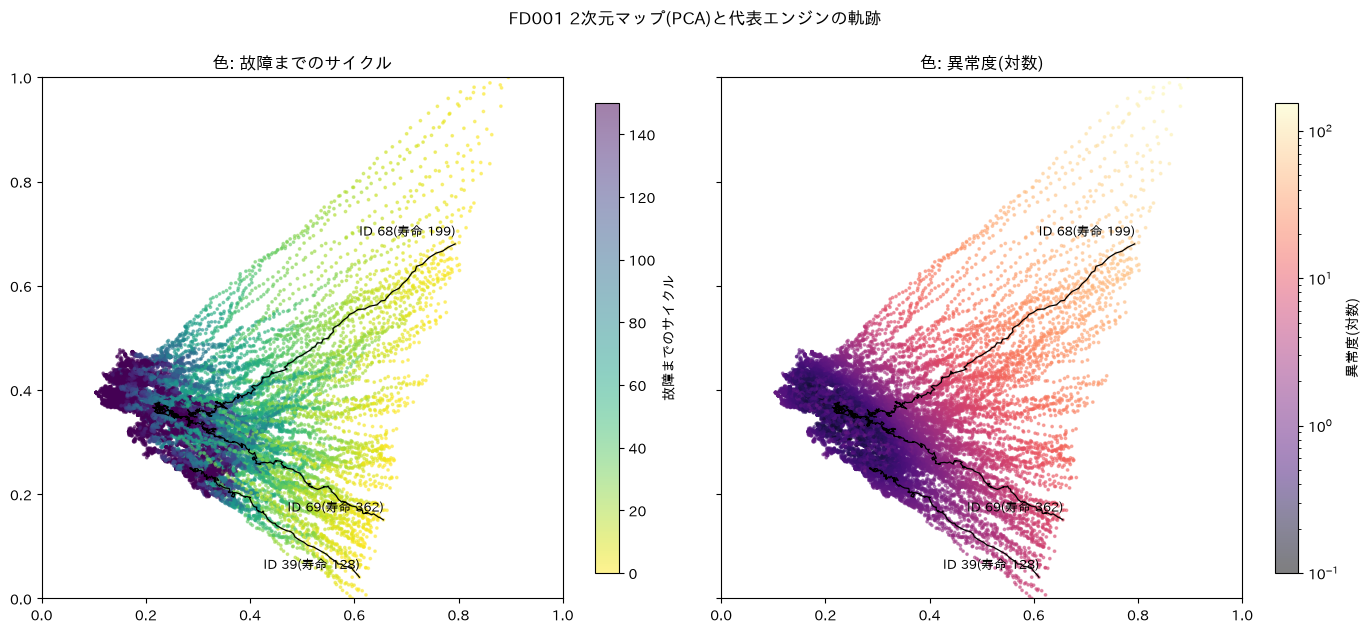

In [12]:
# 寿命が最短・中央値・最長のエンジンの軌跡を重ねる(同値は ID の小さい方)
sorted_life = life.sort_values(kind="stable")
ENGINES = [int(sorted_life.index[k]) for k in (0, len(sorted_life) // 2, -1)]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharex=True, sharey=True)
panels = [
    ("RUL", "故障までのサイクル", dict(cmap="viridis_r", vmax=150)),
    ("anomaly", "異常度(対数)", dict(cmap="magma", norm=plt.matplotlib.colors.LogNorm(vmin=0.1))),
]
for ax, (col, label, kw) in zip(axes, panels):
    sc = ax.scatter(df["x"], df["y"], c=df[col].clip(lower=0.1) if col == "anomaly" else df[col],
                    s=3, alpha=0.5, **kw)
    fig.colorbar(sc, ax=ax, label=label, shrink=0.8)
    for eid in ENGINES:
        g = df[df["エンジンID"] == eid]
        ax.plot(g["x"], g["y"], color="black", linewidth=0.9)
        ax.annotate(f"ID {eid}(寿命 {life[eid]})", g[["x", "y"]].iloc[-1], fontsize=9,
                    xytext=(0, 6), textcoords="offset points", ha="right")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_title(f"色: {label}")
fig.suptitle(f"{DATASET} 2次元マップ({MAP_METHOD.upper()})と代表エンジンの軌跡")
fig.tight_layout()
plt.show()

## 6. JSON 書き出し

In [13]:
round_list = lambda s, d: np.round(np.asarray(s, dtype=float), d).tolist()

data = {
    "meta": {
        "dataset": DATASET,
        "sensors": sensors,
        "n_healthy": N_HEALTHY,
        "window": WINDOW,
        "n_components": n_comp,
        "limit_quantile": LIMIT_Q,
        "map_method": MAP_METHOD,
        "fields": {
            "x, y": "2次元マップの座標(0〜1、縦横同じ倍率)",
            "anomaly": "異常度 = max(t2, spe)。1 以上で管理限界超え",
            "t2": "ホテリングの T² / 管理限界",
            "spe": "SPE(Q統計量)/ 管理限界",
            "z": "センサーごとの正常時からのずれ(移動平均後のσ)。順番は sensors と同じ",
        },
    },
    "engines": [
        {
            "id": int(eid),
            "life": int(len(g)),
            "x": round_list(g["x"], 3),
            "y": round_list(g["y"], 3),
            "anomaly": round_list(g["anomaly"], 3),
            "t2": round_list(g["t2"], 3),
            "spe": round_list(g["spe"], 3),
            "z": np.round(z_ma.loc[g.index].to_numpy(), 2).tolist(),
        }
        for eid, g in df.groupby("エンジンID")
    ],
}

OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
with open(OUT_PATH, "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, separators=(",", ":"))
print(f"書き出し: {OUT_PATH}({OUT_PATH.stat().st_size / 1e6:.2f} MB)")

書き出し: ../web/public/data.json(2.19 MB)


In [14]:
# 読み戻して、配列の長さと値がそろっているか確認する
with open(OUT_PATH, encoding="utf-8") as f:
    loaded = json.load(f)

assert len(loaded["engines"]) == len(life)
for e in loaded["engines"]:
    assert all(len(e[k]) == e["life"] for k in ["x", "y", "anomaly", "t2", "spe", "z"])
    assert all(len(row) == len(loaded["meta"]["sensors"]) for row in e["z"])

e = loaded["engines"][0]
print(f"エンジン {e['id']}(寿命 {e['life']}): 最初の異常度 {e['anomaly'][0]}, 故障時の異常度 {e['anomaly'][-1]}")
print("OK")

エンジン 1(寿命 192): 最初の異常度 0.412, 故障時の異常度 5.757
OK
